# **TP4** 
# UC08 - Analyse des données et visualisation

## Démarrage

### Imports, session, chemins

In [2]:
import os
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("TP4-Retail-Intelligence_Analyse")
    .master("local[*]")
    .getOrCreate()
)

In [8]:
BASE = os.path.expanduser("~/Documents/IPSSI/DataLake Warehouse Lakehouse/TP/J3/data")

ventes   = spark.read.parquet("file://" + BASE + "/silver/store_sales")
produits = spark.read.parquet("file://" + BASE + "/silver/item")
print(ventes.columns)
ventes.printSchema()

['cle_date', '_c1', 'id_produit', '_c3', '_c4', '_c5', '_c6', '_c7', '_c8', 'num_ticket', 'quantite', '_c11', '_c12', 'prix_vente', '_c14', '_c15', '_c16', '_c17', '_c18', '_c19', '_c20', '_c21', 'profit', 'date_vente', 'vente_a_perte', 'prix_nul', 'ligne_id']
root
 |-- cle_date: integer (nullable = true)
 |-- _c1: integer (nullable = true)
 |-- id_produit: integer (nullable = true)
 |-- _c3: integer (nullable = true)
 |-- _c4: integer (nullable = true)
 |-- _c5: integer (nullable = true)
 |-- _c6: integer (nullable = true)
 |-- _c7: integer (nullable = true)
 |-- _c8: integer (nullable = true)
 |-- num_ticket: integer (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- _c11: double (nullable = true)
 |-- _c12: double (nullable = true)
 |-- prix_vente: double (nullable = true)
 |-- _c14: double (nullable = true)
 |-- _c15: double (nullable = true)
 |-- _c16: double (nullable = true)
 |-- _c17: double (nullable = true)
 |-- _c18: double (nullable = true)
 |-- _c19: double (n

# Calcul des KPIs

## Stats descriptives

Utilisation du jeu de données store_sales en silver pour les analyses suivantes

### Vérification des schémas et volumes

In [6]:
print("Lignes            :", ventes.count())
print("Tickets distincts :", ventes.select("num_ticket").distinct().count())
print("Produits distincts:", ventes.select("id_produit").distinct().count())
print("Magasins distincts:", ventes.select("_c7").distinct().count())

Lignes            : 667579
Tickets distincts : 89100
Produits distincts: 17820
Magasins distincts: 12
root
 |-- cle_date: integer (nullable = true)
 |-- _c1: integer (nullable = true)
 |-- id_produit: integer (nullable = true)
 |-- _c3: integer (nullable = true)
 |-- _c4: integer (nullable = true)
 |-- _c5: integer (nullable = true)
 |-- _c6: integer (nullable = true)
 |-- _c7: integer (nullable = true)
 |-- _c8: integer (nullable = true)
 |-- num_ticket: integer (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- _c11: double (nullable = true)
 |-- _c12: double (nullable = true)
 |-- prix_vente: double (nullable = true)
 |-- _c14: double (nullable = true)
 |-- _c15: double (nullable = true)
 |-- _c16: double (nullable = true)
 |-- _c17: double (nullable = true)
 |-- _c18: double (nullable = true)
 |-- _c19: double (nullable = true)
 |-- _c20: double (nullable = true)
 |-- _c21: double (nullable = true)
 |-- profit: double (nullable = true)
 |-- date_vente: date (nullable =

### Valeurs min et max

In [7]:
ventes.agg(
    F.min("quantite").alias("quantite_min"),   F.max("quantite").alias("quantite_max"),
    F.min("prix_vente").alias("prix_min"),     F.max("prix_vente").alias("prix_max"),
    F.min("_c20").alias("net_min"),            F.max("_c20").alias("net_max"),
    F.min("date_vente").alias("date_min"),     F.max("date_vente").alias("date_max"),
).show()

+------------+------------+--------+--------+-------+-------+----------+----------+
|quantite_min|quantite_max|prix_min|prix_max|net_min|net_max|  date_min|  date_max|
+------------+------------+--------+--------+-------+-------+----------+----------+
|           1|         100|     0.0|   199.3|    0.0|18745.0|2001-01-01|2005-12-13|
+------------+------------+--------+--------+-------+-------+----------+----------+



### Moyenne et médianes

In [9]:
ventes.agg(
    F.avg("quantite").alias("quantite_moyenne"), F.expr("percentile(quantite, 0.5)").alias("quantite_mediane"),
    F.avg("prix_vente").alias("prix_moyen"),     F.expr("percentile(prix_vente, 0.5)").alias("prix_median"),
    F.avg("_c20").alias("net_moyen"),            F.expr("percentile(_c20, 0.5)").alias("net_median"),
).show()

+------------------+----------------+-----------------+-----------+------------------+----------+
|  quantite_moyenne|quantite_mediane|       prix_moyen|prix_median|         net_moyen|net_median|
+------------------+----------------+-----------------+-----------+------------------+----------+
|50.564014146640325|            51.0|37.86369706057256|      27.69|1723.4358575838985|    878.54|
+------------------+----------------+-----------------+-----------+------------------+----------+



### Sommes des mesures additives

In [10]:
ventes.agg(
    F.sum("quantite").alias("quantite_totale"),
    F.sum("_c15").alias("ca_brut"),
    F.sum("_c20").alias("ca_net"),
).show()

+---------------+--------------------+--------------------+
|quantite_totale|             ca_brut|              ca_net|
+---------------+--------------------+--------------------+
|       33755474|1.2772240046099997E9|1.1505295863700013E9|
+---------------+--------------------+--------------------+



### Répartition par catégorie

In [11]:
vc = ventes.join(produits.select("id_produit", "categorie"), on="id_produit", how="left")

print("Lignes avant  :", ventes.count())
print("Lignes après  :", vc.count())
print("Sans catégorie:", vc.filter(F.col("categorie").isNull()).count())

Lignes avant  : 667579
Lignes après  : 667579
Sans catégorie: 0


In [12]:
total = ventes.agg(F.sum("_c20")).first()[0]

(vc.groupBy("categorie")
   .agg(F.count("*").alias("lignes"),
        F.sum("quantite").alias("quantite"),
        F.sum("_c20").alias("ca_net"))
   .withColumn("part_pct", F.round(100 * F.col("ca_net") / total, 2))
   .orderBy(F.desc("ca_net"))
   .show(truncate=False))

+------------------------+------+--------+--------------------+--------+
|categorie               |lignes|quantite|ca_net              |part_pct|
+------------------------+------+--------+--------------------+--------+
|Music                   |301236|15238374|5.196666938399998E8 |45.17   |
|Books                   |177671|9007511 |3.071515032500002E8 |26.7    |
|Movies & TV             |43376 |2189279 |7.473589189E7       |6.5     |
|Clothing & Accessories  |32372 |1640550 |5.675485582000002E7 |4.93    |
|Electronics             |32619 |1632098 |5.571508748999999E7 |4.84    |
|Home & Kitchen          |24380 |1226839 |4.126051111000002E7 |3.59    |
|Sports & Outdoors       |23911 |1209305 |4.092693833E7       |3.56    |
|Toys & Games            |16121 |809999  |2.7437825330000002E7|2.38    |
|Tools & Home Improvement|15893 |801519  |2.6880279310000014E7|2.34    |
+------------------------+------+--------+--------------------+--------+



### Evolution dans le temps

In [17]:
temps = (ventes.withColumn("annee", F.year("date_vente"))
               .withColumn("mois",  F.month("date_vente")))

(temps.groupBy("annee")
      .agg(F.countDistinct("date_vente").alias("jours"),
           F.sum("_c20").alias("ca_net"))
      .withColumn("ca_net_par_jour", F.round(F.col("ca_net") / F.col("jours"), 0))
      .orderBy("annee")
      .show())

+-----+-----+--------------------+---------------+
|annee|jours|              ca_net|ca_net_par_jour|
+-----+-----+--------------------+---------------+
| 2001|  365|      2.3249865983E8|       636983.0|
| 2002|  365|2.3094726582000005E8|       632732.0|
| 2003|  365|2.3357518562999997E8|       639932.0|
| 2004|  366|2.3434493428999996E8|       640287.0|
| 2005|  347|2.1916354079999998E8|       631595.0|
+-----+-----+--------------------+---------------+



## Analyses métier

### I. Différences entre magasins

**1 - Tableau par magasin**

In [18]:
mag = (ventes.groupBy("_c7")
       .agg(F.sum("_c20").alias("ca_net"),
            F.countDistinct("num_ticket").alias("tickets"),
            F.count("*").alias("lignes"))
       .toPandas().rename(columns={"_c7": "magasin"}))
mag["panier_moyen"]      = mag.ca_net / mag.tickets          # tickets, pas lignes
mag["part_pct"]          = 100 * mag.ca_net / mag.ca_net.sum()
mag["ecart_moyenne_pct"] = 100 * (mag.ca_net / mag.ca_net.mean() - 1)
mag = mag.sort_values("ca_net", ascending=False).reset_index(drop=True)
mag.round(2)

/home/pauline/project_retail-intelligence/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,magasin,ca_net,tickets,lignes,panier_moyen,part_pct,ecart_moyenne_pct
0,7,98950137.76,7645,57589,12943.12,8.60,3.20
1,4,96770105.59,7462,56211,12968.39,8.41,0.93
2,9,96748356.68,7435,56040,13012.56,8.41,0.91
3,0,96727851.94,7456,56018,12973.16,8.41,0.89
4,8,96578622.89,7414,55737,13026.52,8.39,0.73
5,3,96063990.59,7396,55397,12988.64,8.35,0.19
6,1,95929844.66,7422,55676,12925.07,8.34,0.05
7,11,95607843.48,7449,55473,12834.99,8.31,-0.28
8,6,94751173.08,7284,54574,13008.12,8.24,-1.17
9,10,94263977.55,7409,55109,12722.90,8.19,-1.68


**2 - Ecart entre le meilleur et le dernier**

In [19]:
print(round(100 * (mag.ca_net.max() / mag.ca_net.min() - 1), 2), "%")

5.22 %


**3 - Le classement est-il stable d'une année sur l'autre ?**

In [20]:
ma = temps.groupBy("_c7", "annee").agg(F.sum("_c20").alias("ca_net")).toPandas()
ma.pivot(index="_c7", columns="annee", values="ca_net").rank(ascending=False).astype(int)

/home/pauline/project_retail-intelligence/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


annee,2001,2002,2003,2004,2005
_c7,,,,,
0,5,6,2,9,2
1,1,9,11,6,4
2,9,4,10,11,10
3,8,11,5,3,8
4,4,5,4,7,5
5,7,10,7,8,12
6,2,3,12,10,11
7,3,1,1,1,7
8,6,12,3,2,9


### II. Produits qui contribuent le plus

**1 - Classement des produits**

In [21]:
n0 = ventes.count()
vc = ventes.join(produits.select("id_produit", "categorie"), on="id_produit", how="left")
assert vc.count() == n0          # la jointure ne doit ni perdre ni dupliquer de lignes

prod = (vc.groupBy("id_produit", "categorie")
        .agg(F.sum("_c20").alias("ca_net"), F.count("*").alias("lignes"))
        .toPandas().sort_values("ca_net", ascending=False).reset_index(drop=True))
prod["part_pct"]         = 100 * prod.ca_net / prod.ca_net.sum()
prod["part_cumulee_pct"] = prod.part_pct.cumsum()
prod.head(10).round(2)

/home/pauline/project_retail-intelligence/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,id_produit,categorie,ca_net,lignes,part_pct,part_cumulee_pct
0,10000,Home & Kitchen,15408393.55,9029,1.34,1.34
1,10003,Electronics,14933870.10,8761,1.30,2.64
2,10001,Music,14572124.66,8269,1.27,3.90
3,10002,Music,12817437.86,7505,1.11,5.02
4,17502,Books,3336529.83,1878,0.29,5.31
5,10579,Music,3250367.57,1767,0.28,5.59
6,8601,Clothing & Accessories,3238749.92,1761,0.28,5.87
7,5618,Music,3212955.42,1867,0.28,6.15
8,2651,Music,3172287.79,1730,0.28,6.43
9,16513,Music,3162636.37,1817,0.27,6.70


**2 - Concentration**

In [22]:
for n in [4, 10, 100, 1000]:
    print("Top", n, "produits :", round(prod.part_cumulee_pct.iloc[n-1], 2), "% du CA")
print("Produits pour atteindre 50 % du CA :", int((prod.part_cumulee_pct < 50).sum() + 1), "sur", len(prod))

Top 4 produits : 5.02 % du CA
Top 10 produits : 6.7 % du CA
Top 100 produits : 28.12 % du CA
Top 1000 produits : 49.3 % du CA
Produits pour atteindre 50 % du CA : 1133 sur 17820


**3 - Distribution du CA et du nombre de lignes par produit**

In [23]:
prod[["ca_net", "lignes"]].describe(percentiles=[.5, .9, .99]).round(0)

,ca_net,lignes
count,17820.0,17820.0
mean,64564.0,37.0
std,317939.0,184.0
min,2787.0,6.0
50%,34949.0,21.0
90%,54978.0,28.0
99%,1067531.0,613.0
max,15408394.0,9029.0


# Visualisations

## Style commun et dossier de sauvgarde

In [28]:
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})
BLEU, GRIS, ROUGE = "#2a6fb0", "#b8bfc7", "#c2410c"
SOURCE = "Source : Silver store_sales (TPCx-BB, données synthétiques), CA net HT = _c20, 2001-01-01 → 2005-12-13"

# adapte ce chemin à ton dépôt (dossier J4_Analyse_Azure/analytics/visualizations)
OUT = Path(os.path.expanduser("/home/pauline/Documents/IPSSI/DataLake Warehouse Lakehouse/TP/J4/analytics/visualizations"))
OUT.mkdir(parents=True, exist_ok=True)

## CA par magasin

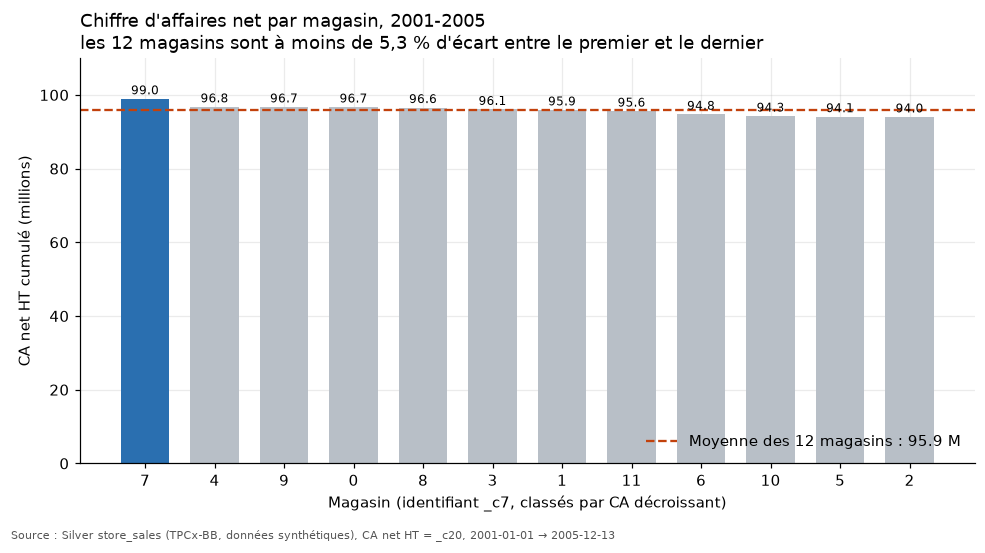

In [29]:
d = mag.sort_values("ca_net", ascending=False).reset_index(drop=True)
moy = d.ca_net.mean() / 1e6

fig, ax = plt.subplots(figsize=(9, 5))
couleurs = [BLEU if m == 7 else GRIS for m in d.magasin]
bars = ax.bar(d.magasin.astype(str), d.ca_net / 1e6, color=couleurs, width=0.7)
ax.axhline(moy, color=ROUGE, lw=1.5, ls="--", label=f"Moyenne des 12 magasins : {moy:.1f} M")
ax.set_ylim(0, 110)   # une barre doit partir de zéro, sinon l'écart paraît énorme
ax.set_title("Chiffre d'affaires net par magasin, 2001-2005\n"
             "les 12 magasins sont à moins de 5,3 % d'écart entre le premier et le dernier", loc="left")
ax.set_xlabel("Magasin (identifiant _c7, classés par CA décroissant)")
ax.set_ylabel("CA net HT cumulé (millions)")
for b, v in zip(bars, d.ca_net / 1e6):
    ax.text(b.get_x() + b.get_width()/2, v + 1.2, f"{v:.1f}", ha="center", fontsize=8)
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, 0.01, SOURCE, fontsize=7.5, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "v1_ca_par_magasin.png"); plt.show()

## Concentration CA par produit

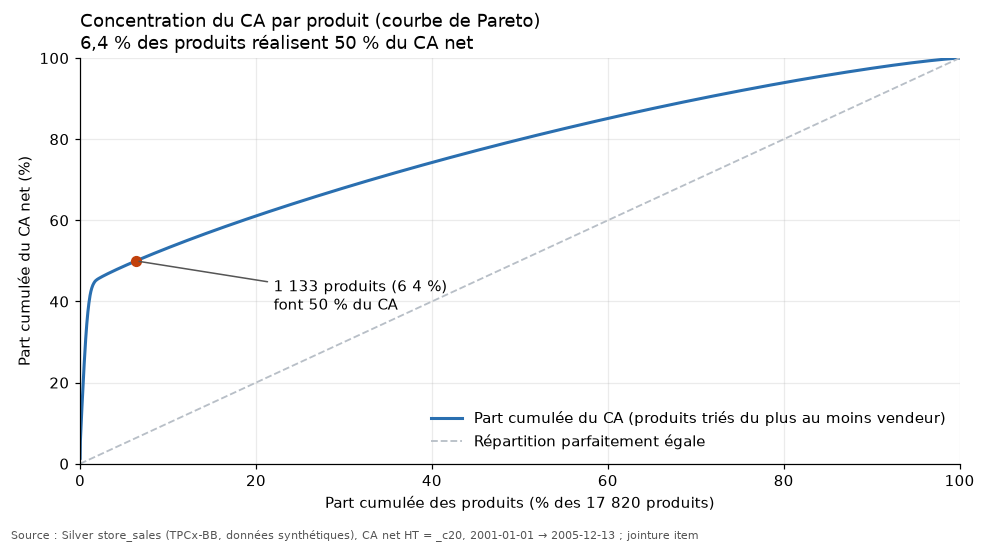

In [30]:
n   = len(prod)
x   = 100 * (prod.index + 1) / n          # % cumulé des produits
y   = prod.part_cumulee_pct               # % cumulé du CA
n50 = int((y < 50).sum() + 1)
pct50 = f"{100*n50/n:.1f}".replace(".", ",")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, y, color=BLEU, lw=2, label="Part cumulée du CA (produits triés du plus au moins vendeur)")
ax.plot([0, 100], [0, 100], color=GRIS, lw=1.2, ls="--", label="Répartition parfaitement égale")
ax.scatter([100*n50/n], [50], color=ROUGE, zorder=3, s=40)
ax.annotate(f"{n50:,} produits ({pct50} %)\nfont 50 % du CA".replace(",", " "),
            xy=(100*n50/n, 50), xytext=(22, 38), arrowprops=dict(arrowstyle="-", color="#555"))
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title(f"Concentration du CA par produit (courbe de Pareto)\n{pct50} % des produits réalisent 50 % du CA net", loc="left")
ax.set_xlabel(f"Part cumulée des produits (% des {n:,} produits)".replace(",", " "))
ax.set_ylabel("Part cumulée du CA net (%)")
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, 0.01, SOURCE + " ; jointure item", fontsize=7.5, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "v2_pareto_produits.png"); plt.show()

## Evolution du CA par jour, mois par mois

/home/pauline/project_retail-intelligence/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


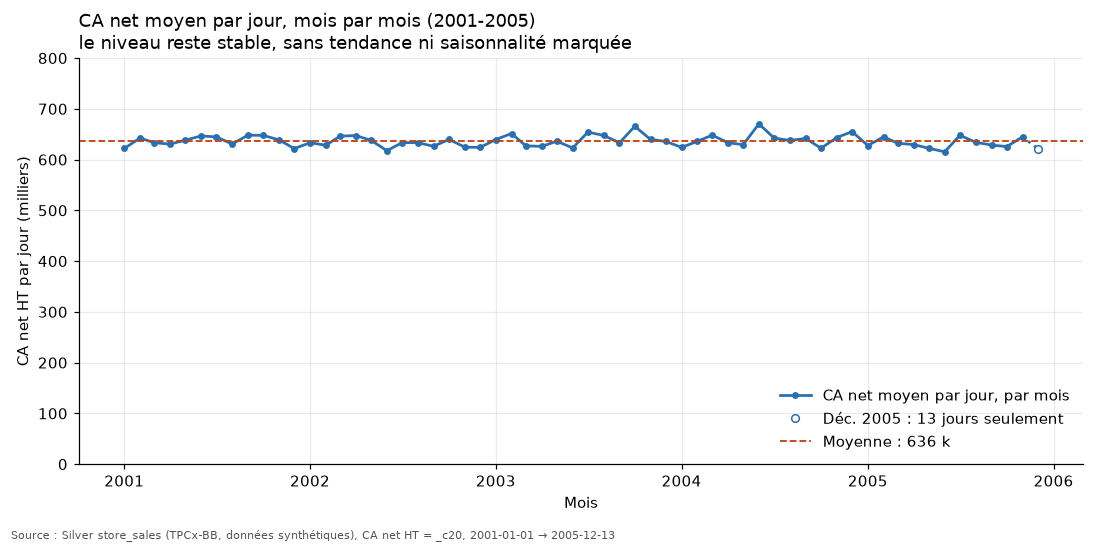

In [31]:
mois = (temps.groupBy("annee", "mois")
        .agg(F.countDistinct("date_vente").alias("jours"), F.sum("_c20").alias("ca_net"))
        .toPandas().sort_values(["annee", "mois"]))
mois["ca_par_jour"] = mois.ca_net / mois.jours
mois["date"] = pd.to_datetime(dict(year=mois.annee, month=mois.mois, day=1))

ok  = mois[~((mois.annee == 2005) & (mois.mois == 12))]   # mois complets
dec = mois[(mois.annee == 2005) & (mois.mois == 12)]       # décembre 2005 : 13 jours

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ok.date, ok.ca_par_jour/1e3, color=BLEU, lw=1.8, marker="o", ms=3.5, label="CA net moyen par jour, par mois")
ax.plot([ok.date.iloc[-1], dec.date.iloc[0]], [ok.ca_par_jour.iloc[-1]/1e3, dec.ca_par_jour.iloc[0]/1e3],
        color=BLEU, lw=1.8, ls=":")
ax.plot(dec.date, dec.ca_par_jour/1e3, marker="o", mfc="white", color=BLEU, ms=5, ls="none",
        label="Déc. 2005 : 13 jours seulement")
ax.axhline(ok.ca_par_jour.mean()/1e3, color=ROUGE, ls="--", lw=1.2, label=f"Moyenne : {ok.ca_par_jour.mean()/1e3:.0f} k")
ax.set_ylim(0, 800)
ax.set_title("CA net moyen par jour, mois par mois (2001-2005)\n"
             "le niveau reste stable, sans tendance ni saisonnalité marquée", loc="left")
ax.set_xlabel("Mois"); ax.set_ylabel("CA net HT par jour (milliers)")
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, 0.01, SOURCE, fontsize=7.5, color="#555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUT / "v3_evolution_ca_par_jour.png"); plt.show()

## Ecriture Azure-ready

In [32]:
import glob, shutil, json, hashlib
from datetime import datetime, timezone

DEMO = Path(os.path.expanduser("~/Documents/IPSSI/DataLake Warehouse Lakehouse/TP/J4/azure/demo/ca_par_mois"))
TMP  = DEMO.parent / "_tmp"
shutil.rmtree(DEMO.parent, ignore_errors=True); DEMO.mkdir(parents=True)

df = spark.read.parquet("file://" + BASE + "/gold/ca_par_mois")
df.coalesce(1).write.mode("overwrite").parquet("file://" + str(TMP))
src = glob.glob(str(TMP / "part-*.parquet"))[0]
cible = DEMO / "ca_par_mois.parquet"
shutil.copy(src, cible); shutil.rmtree(TMP)

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()

manifest = {"fichier": cible.name, "taille_octets": cible.stat().st_size, "sha256": sha256(cible),
            "lignes": df.count(), "source": "gold/ca_par_mois (TP3, CA brut _c15)",
            "prepare_le": datetime.now(timezone.utc).isoformat(timespec="seconds")}
(DEMO / "_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(manifest, indent=2))
print("Fichiers prêts dans :", DEMO)

{
  "fichier": "ca_par_mois.parquet",
  "taille_octets": 2182,
  "sha256": "1ef94fcaa57cdb94d852802e2c0bb89a846720a07001eff7619b5bb3cb9b61ff",
  "lignes": 60,
  "source": "gold/ca_par_mois (TP3, CA brut _c15)",
  "prepare_le": "2026-11-20T16:32:53+00:00"
}
Fichiers prêts dans : /home/pauline/Documents/IPSSI/DataLake Warehouse Lakehouse/TP/J4/azure/demo/ca_par_mois


### Comparaison des SHA256

In [34]:
telecharge = Path.home() / "Downloads" / "ca_par_mois.parquet"  
print("SHA-256 manifeste     :", manifest["sha256"])
print("SHA-256 téléchargé    :", sha256(telecharge))
print("Identiques            :", sha256(telecharge) == manifest["sha256"])

SHA-256 manifeste     : 1ef94fcaa57cdb94d852802e2c0bb89a846720a07001eff7619b5bb3cb9b61ff
SHA-256 téléchargé    : 1ef94fcaa57cdb94d852802e2c0bb89a846720a07001eff7619b5bb3cb9b61ff
Identiques            : True
